# 2. DeepONet 대리모형 — 성능 · 시각화 · 가격오차

이론가(MC)를 재현하는 **대리모형**의 결과를 한 장에 모은다. 기준 모형은 **Direct + 단조손실**,
기초자산 1·2·3개를 통합 학습한 것이다. 평가는 walk-forward 4폴드 · 5시드 · OOS 전량.

| | 값 |
|---|---|
| 전체 R² | **0.9561** |
| 전체 MAPE | **0.512%** |
| 추론 속도 | 2-4절에서 실측 |

**1단계 성능은 MC 이론가 재현만으로 잰다.** 공정가 지표를 섞지 않는다 — 4절에서 공정가 격차를
따로 보되, 그건 모델 성능이 아니라 이론가와 시장가의 차이다.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from util import file_manager as fm, plot as _plot      # import 만으로 dpi400·투명·PPT 밴드

MODEL, ONLY3, XGB = "Direct+m (1·2·3)", "Direct+m (3star only)", "XGBoost (1·2·3)"
C_MC, C_NEW, C_OLD, C_XGB = "#e07a5f", "#1f6f9c", "#9b5de5", "#8d99ae"

L = pd.read_csv(fm.stat("allstar_level"), encoding="utf-8-sig")
S = pd.read_csv(fm.stat("allstar_slope"), encoding="utf-8-sig")
X = pd.read_csv(fm.stat("xsec_resid"), encoding="utf-8-sig")
U = pd.read_csv(fm.stat("stage1_by_underlying"), encoding="utf-8-sig")
print("수준 지표", L.shape, "| 기울기", S.shape, "| 횡단면 잔차회귀", X.shape, "| 기초자산별", U.shape)

수준 지표 (28, 12) | 기울기 (18, 10) | 횡단면 잔차회귀 (66, 11) | 기초자산별 (21, 7)


## 2-1. 수준 정확도 — 기초자산 수별

기초자산 1·2·3개를 **함께** 학습한 것과 3개짜리만 학습한 것을 같은 폴드·같은 시험집합에서 비교한다.
막대는 R² 와 MAPE 둘만 쓴다 (MAE·편향은 아래 표로).

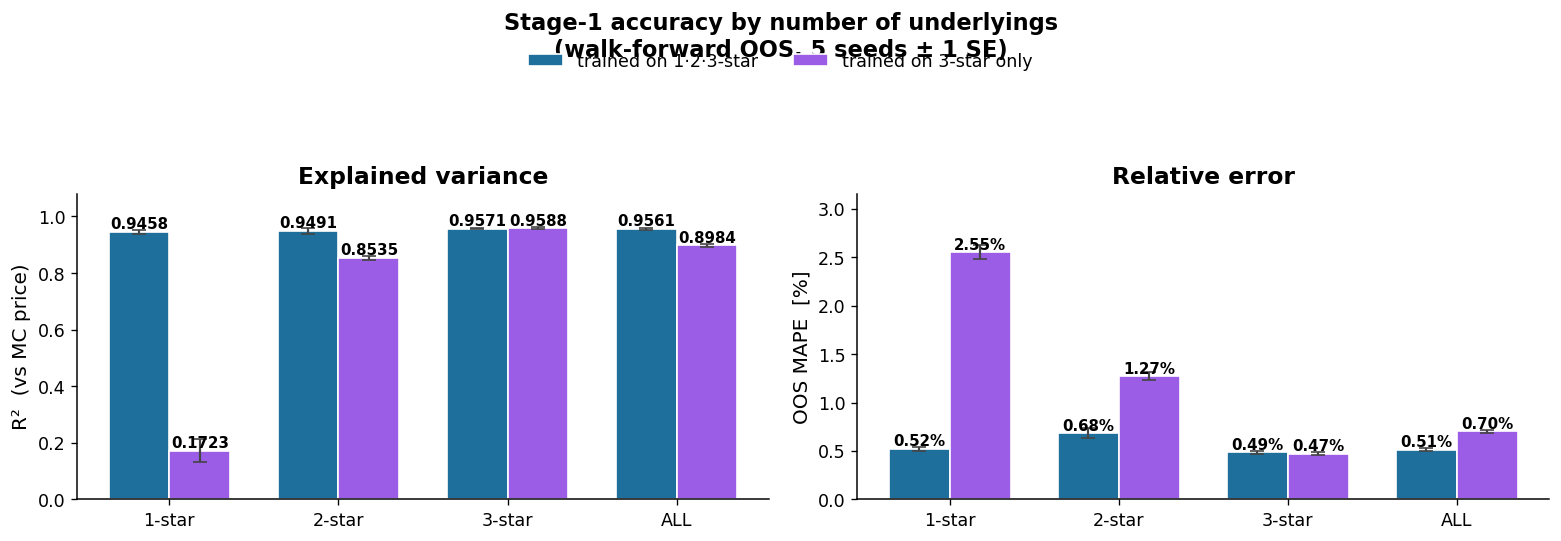

group                 model     n     R2  R2_se   MAPE      MAE      bias
  ALL      Direct+m (1·2·3) 29743 0.9561 0.0036 0.5118  48.8400   -3.8372
  ALL Direct+m (3star only) 29743 0.8984 0.0048 0.7017  67.0171  -27.4921
  ALL       XGBoost (1·2·3) 29743 0.9044 0.0008 0.7507  71.3661  -14.9091
1star      Direct+m (1·2·3)  1947 0.9458 0.0065 0.5224  49.8467   -7.2948
1star Direct+m (3star only)  1947 0.1723 0.0410 2.5543 244.9208 -214.7433
1star       XGBoost (1·2·3)  1947 0.8451 0.0040 0.8671  82.4810  -43.6791
2star      Direct+m (1·2·3)  3469 0.9491 0.0095 0.6821  63.6429   15.8077
2star Direct+m (3star only)  3469 0.8535 0.0067 1.2740 119.1624  -59.5301
2star       XGBoost (1·2·3)  3469 0.8581 0.0014 1.0107  92.1935    5.0349
3star      Direct+m (1·2·3) 24327 0.9571 0.0026 0.4867  46.6486   -6.3618
3star Direct+m (3star only) 24327 0.9588 0.0032 0.4719  45.3428   -7.9369
3star       XGBoost (1·2·3) 24327 0.9161 0.0010 0.7043  67.5065  -15.4505


In [2]:
G = ["1star", "2star", "3star", "ALL"]
T = L.set_index(["group", "model"])
fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.6))
x = np.arange(len(G)); w = .36
for a, col, yl, ttl, fv in [(ax[0], "R2", "R²  (vs MC price)", "Explained variance", "{:.4f}"),
                            (ax[1], "MAPE", "OOS MAPE  [%]", "Relative error", "{:.2f}%")]:
    for j, (m, c, nm) in enumerate([(MODEL, C_NEW, "trained on 1·2·3-star"),
                                    (ONLY3, C_OLD, "trained on 3-star only")]):
        v = [T.loc[(g, m), col] for g in G]
        e = [T.loc[(g, m), col + "_se"] for g in G]
        a.bar(x + (j - .5) * w, v, w, color=c, edgecolor="white", lw=1, yerr=e, capsize=4,
              error_kw=dict(lw=1.3, ecolor="#444"), label=nm)
        for xx, val in zip(x + (j - .5) * w, v):
            a.text(xx, val, fv.format(val), ha="center", va="bottom", fontsize=9, fontweight="bold")
    a.set_xticks(x); a.set_xticklabels([g.replace("star", "-star") for g in G])
    a.set_ylabel(yl); a.set_title(ttl, fontweight="bold"); a.margins(y=.20)
    if col == "R2":
        a.set_ylim(0, 1.08)
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(.5, .935))
fig.suptitle("Stage-1 accuracy by number of underlyings\n(walk-forward OOS, 5 seeds ± 1 SE)",
             fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, .875])
fig.savefig(fm.image("model_level"), dpi=200, bbox_inches="tight")
plt.show()

print(L[L.model.isin([MODEL, ONLY3, XGB])][
    ["group", "model", "n", "R2", "R2_se", "MAPE", "MAE", "bias"]].round(4).to_string(index=False))

## 2-2. 계약조건 반응 — 전수 횡단면

계약조건에 가격이 **MC 와 같은 방식으로 반응하는가**. 기준상품 12개 섭동격자는 표집오차가 커서
모델 간 순위를 가리지 못했다 (리자드 요인은 상품 6개로만 측정됐고 부트 구간이 [0.78, 3.40]).

그래서 OOS 전수로 잰다: **(모델 − MC) 를 계약조건에 회귀**하고, 기울기가 0이면 MC 와 동일 반응이다.
표준오차는 발행일 군집으로 보정한다. 공통 교란은 차분에서 상쇄된다.

주의: 횡단면 기울기 자체는 편미분이 아니라 **연관**이다. 절대값을 민감도로 읽으면 안 되고,
같은 상품 위의 MC 선 대비 모델 선의 차이만 읽는다.

In [3]:
z = X[(X.nstar.astype(str) == "3") & (X.model == MODEL)].copy()
z["MC 대비 %"] = (z.rel * 100).round(1)
z["유의"] = np.where(z.t.abs() >= 1.96, "O", "")
print("3스타 OOS 전수 — (모델 − MC) ~ 계약조건")
print(z[["factor", "n", "MC_slope", "resid_slope", "se", "MC 대비 %", "t", "유의"]].round(2).to_string(index=False))

3스타 OOS 전수 — (모델 − MC) ~ 계약조건
         factor     n  MC_slope  resid_slope     se  MC 대비 %     t 유의
     KI barrier 24327    110.42        -7.71   3.10     -7.0 -2.49  O
coupon (annual) 24327  -4872.28       133.72  74.10     -2.7  1.80   
   first strike 24327  -1161.29       -43.58  10.76      3.8 -4.05  O
step-down width 24327   -403.98       -49.31  10.21     12.2 -4.83  O
 lizard barrier  2646   -503.24       412.53  60.17    -82.0  6.86  O
  lizard payout  2646  -2677.72      -133.93 143.11      5.0 -0.94   


## 2-3. 기초자산별 — 지수 vs 개별주식

1단계 MC 재현 기준으로 기초자산별 성능을 가른다. 지수는 촘촘하고 **개별주식이 약점**이다.

      udl   구분     n     R2   MAPE      MAE     bias
000660.KS 개별주식   360 0.8369 1.2318 110.0636   2.7174
   ^KS200   지수 11973 0.9609 0.3820  36.7471 -14.4756
    ^N225   지수  8899 0.9687 0.4056  39.2300 -12.3220
    ^GSPC   지수 20984 0.9688 0.3789  36.4087  -5.4899
^STOXX50E   지수 20956 0.9739 0.3578  34.4447  -5.8023
    ^HSCE   지수  8475 0.9770 0.4174  39.3657   0.6635
005930.KS 개별주식   522 0.9785 0.4628  43.1034  12.3843


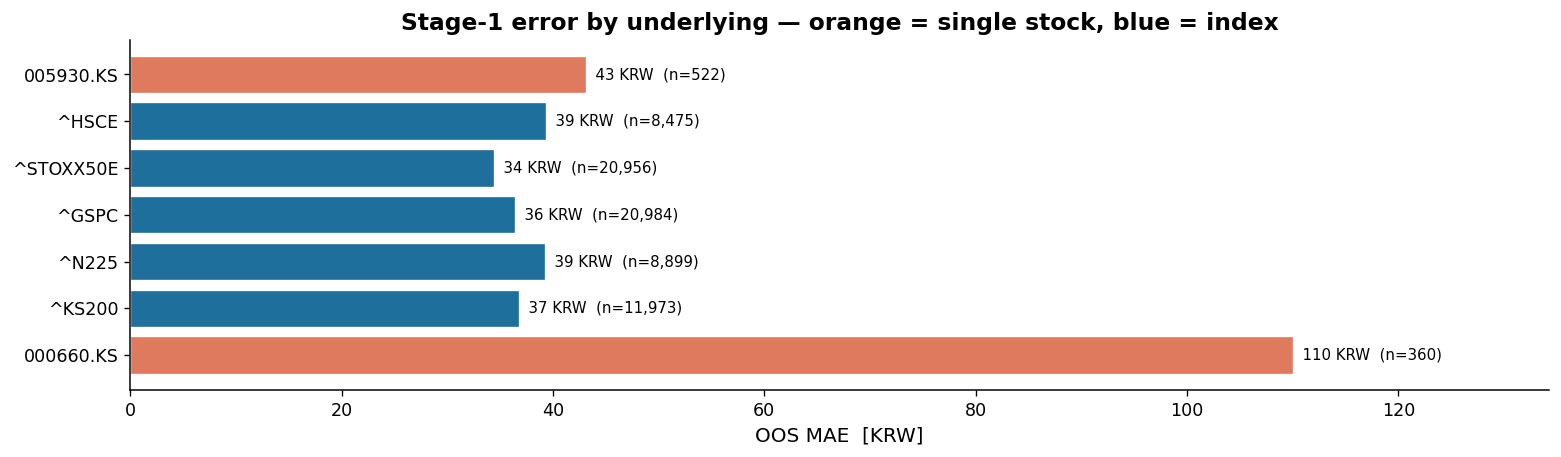

In [4]:
e = U[U.model == "Direct + mono"].sort_values("R2")
e["구분"] = np.where(e.udl.str.startswith("^"), "지수", "개별주식")
print(e[["udl", "구분", "n", "R2", "MAPE", "MAE", "bias"]].round(4).to_string(index=False))

fig, a = plt.subplots(figsize=(13.2, 4.0))
col = [C_NEW if t.startswith("^") else C_MC for t in e.udl]
a.barh(np.arange(len(e)), e.MAE.values, color=col, edgecolor="white", lw=.8)
for i, (v, n) in enumerate(zip(e.MAE.values, e.n.values)):
    a.text(v, i, f"  {v:.0f} KRW  (n={n:,})", va="center", fontsize=9)
a.set_yticks(np.arange(len(e))); a.set_yticklabels(e.udl)
a.set_xlabel("OOS MAE  [KRW]"); a.margins(x=.22)
a.set_title("Stage-1 error by underlying — orange = single stock, blue = index",
            fontweight="bold")
fig.tight_layout()
fig.savefig(fm.image("model_by_underlying"), dpi=200, bbox_inches="tight")
plt.show()

## 2-4. 추론 속도 — MC 대비

대리모형을 쓰는 이유 자체다. 두 쪽을 같은 기계에서 실측한다.

- **MC**: 현행 방법론 프라이서로 상품 하나 (1장과 같은 입력·같은 경로 수)
- **대리모형**: 같은 아키텍처(`CurveOperatorV2`)의 전방계산 처리량

속도는 가중치가 아니라 구조가 정한다. 그래서 체크포인트를 묶지 않고 같은 크기의 망으로 잰다.

In [5]:
import time, yaml, torch
from module.networks import CurveOperatorV2
from module import features as F, curve as CV, dividend as DV, mc_engine as ME
from module.schedule import LZ_BARR_NEUTRAL
from module.mc import load_market

cfg = yaml.safe_load(open(fm.ROOT / "config.yaml", encoding="utf-8"))
P = cfg["networks"]["P"]
dev = "cuda" if torch.cuda.is_available() else "cpu"
NVC, NCON, NCURVE = 7, 51, 10                       # module/data.py 의 열 수

net = CurveOperatorV2(NVC, NCON, P).to(dev).eval()
NB = 8192
cu = torch.randn(NB, NCURVE, device=dev); vc = torch.randn(NB, NVC, device=dev)
cn = torch.randn(NB, NCON, device=dev)
with torch.no_grad():                                # 워밍업 (CUDA 커널 컴파일 제외)
    for _ in range(3):
        net.V(cu, vc, cn)
    if dev == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(20):
        net.V(cu, vc, cn)
    if dev == "cuda":
        torch.cuda.synchronize()
    us_model = (time.perf_counter() - t0) / (20 * NB) * 1e6

# MC 한 건 (1장과 같은 조립)
df1 = pd.read_parquet(fm.DATA / "els3_dataset.parquet").sort_values("isu_ord").reset_index(drop=True)
RET = load_market()["RET"]; KBD = RET["^KS200"].dropna().index
row = df1[df1[["udl1", "udl2", "udl3"]].isin(list(RET)).all(axis=1)].iloc[0]
dt = pd.Timestamp.fromordinal(int(row["isu_ord"])); tks = [row[f"udl{j}"] for j in (1, 2, 3)]
rets = [RET[t] for t in tks]
sig = [F.vol_ewma_lam(r, dt) for r in rets]; corr, _ = F.corr_bd(rets, dt, KBD)
dz = CV.zero_from_date(dt); divlog, *_ = DV.build_div(tks, dt, float(row["tenor"]))
n_ = int(row["nobs"])
kw = dict(seed=int(row["mc_seed"]), c=float(row["coupon"]),
          pmts=[float(row[f"pmt_{j}"]) for j in range(n_)],
          lz_barr=[float(row[f"lz_barr_{j}"]) if row[f"lz_barr_{j}"] < LZ_BARR_NEUTRAL else np.nan
                   for j in range(n_)],
          lz_pmt=[float(row[f"lz_pmt_{j}"]) for j in range(n_)], divlog=divlog)
st = [float(row[f"strk_{j}"]) for j in range(n_)]
ME.mc_daily_t(sig, corr, dz, float(row["B"]), st, float(row["tenor"]), n=40_000, **kw)  # 워밍업
t0 = time.perf_counter()
for _ in range(5):
    ME.mc_daily_t(sig, corr, dz, float(row["B"]), st, float(row["tenor"]), n=40_000, **kw)
s_mc = (time.perf_counter() - t0) / 5

print(f"장치 {dev}")
print(f"  MC (40,000 경로)  상품당 {s_mc * 1e3:8.1f} ms")
print(f"  대리모형          상품당 {us_model:8.3f} us  (배치 {NB:,})")
print(f"  가속              {s_mc * 1e6 / us_model:,.0f} 배")

장치 cuda
  MC (40,000 경로)  상품당     26.8 ms
  대리모형          상품당    0.139 us  (배치 8,192)
  가속              193,544 배


## 2-5. 공정가와 가격오차

대리모형의 목표는 이론가 재현이고, **공정가는 별개의 질문**이다. 여기서는 세 값을 한 줄에 놓는다:
시장 공정가 · MC 이론가 · 모델 예측. 모델이 이론가를 거의 그대로 재현하므로
공정가와의 격차는 사실상 1장에서 본 이론가-공정가 격차와 같다.

In [6]:
g = L[L.model == MODEL].set_index("group")
mc_sd = g.loc["ALL", "mc_sd"]
rows = [dict(구간="모델 − MC (대리모형 오차)", MAE원=g.loc["ALL", "MAE"], 편향원=g.loc["ALL", "bias"]),
        dict(구간="공정가 − MC (이론가 격차, 1장)", MAE원=567.0, 편향원=-427.0)]
D = pd.DataFrame(rows)
D["MC 표준편차 대비"] = (D.MAE원 / mc_sd).round(3)
print(f"MC 가격 표준편차 {mc_sd:.0f}원")
print(D.round(1).to_string(index=False))
print()
print("대리모형 오차는 이론가-공정가 격차의 {:.1%} 수준 — 공정가 설명의 병목은 대리모형이 아니다."
      .format(g.loc["ALL", "MAE"] / 567.0))

MC 가격 표준편차 374원
                   구간  MAE원    편향원  MC 표준편차 대비
    모델 − MC (대리모형 오차)  48.8   -3.8         0.1
공정가 − MC (이론가 격차, 1장) 567.0 -427.0         1.5

대리모형 오차는 이론가-공정가 격차의 8.6% 수준 — 공정가 설명의 병목은 대리모형이 아니다.


## 결론

1. **통합 학습이 필수다.** 3스타만 학습한 모형으로 1스타를 예측하면 R² 0.1723 · MAE 245원으로 무너진다.
   통합하면 0.9458 로 올라가고, 3스타 성능은 0.9588 → 0.9571 로 거의 손실이 없다.
   XGBoost 도 같은 방향으로 무너지므로(전체 R² 0.9044) 이건 아키텍처가 아니라 **표본의 문제**다.
2. **계약조건 반응은 대체로 MC 를 따라간다.** 다만 **리자드 배리어**는 3스타에서 MC 대비
   -82% 로 가장 크게 벗어난다 (저배리어 구간 저평가). 단조손실 대상을
   리자드 지급률에서 **리자드 배리어로 옮기는 것**이 다음 과제다.
3. **개별주식이 약점이다.** 지수는 R² 0.96~0.98 로 촘촘한데 000660.KS 는 0.837 ·
   MAE 110원이다. 개별주식 전용 변동성 지표가 없는 것이 원인 후보다.
4. **공정가 설명의 병목은 대리모형이 아니다.** 대리모형 오차는 이론가-공정가 격차의 한 자릿수 % 수준이다.

**은퇴한 노트북과 그 결론** (이 노트북이 흡수)

| 종전 노트북 | 흡수된 내용 |
|---|---|
| 2_run · 3_evaluate | 학습 · 평가 (2-1절) |
| 11_error_analysis | 오차 분해 (2-4절) |
| 5_segment | 구조별 · 기초자산별 (2-3절) |
| 20_contract_sensitivity | 계약조건 민감도 → 전수 횡단면으로 대체 (2-2절) |
| 12_contract_terms_pricing · 13_causal_increments | 계약조건 효과 식별 → 2-2절의 군집보정 잔차회귀로 통합 |
| 9 · 10 (Bates·IV 앵커 ablation) | 미채택 |